# Эксперименты

Все модели - decoder-only (Llama из transformers, MoE — Mixtral), обучены с нуля на M4 Pro (mps)

In [6]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator


bench = json.load(open('results/benchmark.json'))


def load_run(name):
    run = EventAccumulator(f'runs/{name}')
    run.Reload()

    return run


def summary(names):
    rows = []

    for name in names:
        run = load_run(name)
        config = json.loads(run.Tensors('config/text_summary')[0].tensor_proto.string_val[0])
        speed = run.Scalars('perf/tokens_per_sec')

        rows.append({
            'модель': name,
            'параметров, M': round(config['params'] / 1e6, 1),
            'токенов, M': round(run.Scalars('val/bpc')[-1].step / 1e6),
            'токенов/с': int(np.percentile([s.value for s in speed], 90)),
            'часов': round((speed[-1].wall_time - speed[0].wall_time) / 3600, 1),
            'bits/char': bench[name]['bpc'],
            'acc_calib': bench[name]['summary']['acc_calib'],
        })

    return pd.DataFrame(rows).set_index('модель')


def plot_bpc(names, ylim, by_time=False):
    plt.figure(figsize=(7, 4))

    for name in names:
        points = load_run(name).Scalars('val/bpc')

        if by_time:
            x = [(p.wall_time - points[0].wall_time) / 3600 for p in points]
        else:
            x = [p.step / 1e6 for p in points]

        plt.plot(x, [p.value for p in points], label=name)

    plt.xlabel('часов' if by_time else 'токенов, M')
    plt.ylabel('bits per char на валидации')
    plt.ylim(*ylim)
    plt.legend()
    plt.show()

Главная метрика — bits per char на валидации:
- это лосс в битах на один символ текста, а не на токен
- не зависит от токенизатора, и модели с разными словарями сравнимы
- валидация одна и та же для всех моделей

acc_calib — точность на бенчмарке фактов

## 1. Размер модели

tiny, small, medium на корпусе v1 (46M токенов), словарь 16k.

In [7]:
sizes = ['tiny_v16k', 'small_v16k', 'medium_v16k']

summary(sizes)

,"параметров, M","токенов, M",токенов/с,часов,bits/char,acc_calib
модель,,,,,,
tiny_v16k,8.9,50,55230,0.3,1.3599,0.260
small_v16k,33.9,70,20123,1.0,1.2649,0.365
medium_v16k,68.9,60,11198,1.6,1.2448,0.375


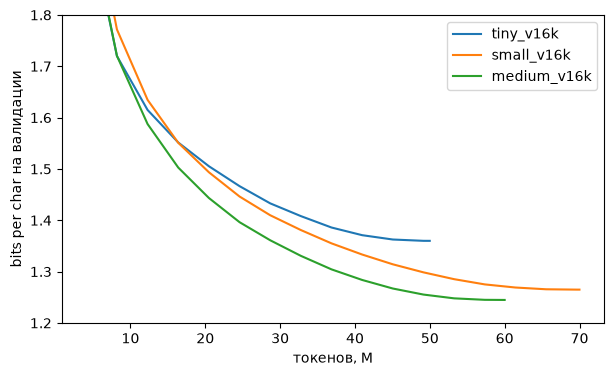

In [3]:
plot_bpc(sizes, (1.2, 1.8))

- Рост модели помогает, но все меньше:
    - tiny -> small (8.9M → 34M) дает −7%
    - small -> medium (34M → 69M) только −1.6%
- medium упирается в данные:
    - в корпусе 46M уникальных токенов
    - по Chinchilla нужно 20 токенов на параметр
    - 69M -> ~1.4B токенов
- Дальше увеличил корпус, но все равно большой простор для скейлинга по данным

## 2. Размер словаря

- tiny
- 50M токенов на трейне
- словарь 8k против 16k

In [8]:
vocabs = ['tiny_v8k', 'tiny_v16k']

summary(vocabs)

,"параметров, M","токенов, M",токенов/с,часов,bits/char,acc_calib
модель,,,,,,
tiny_v8k,6.9,50,72508,0.4,1.3801,0.323
tiny_v16k,8.9,50,55230,0.3,1.3599,0.260


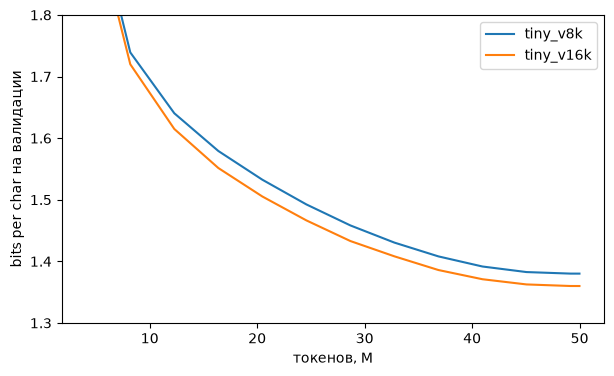

In [9]:
plot_bpc(vocabs, (1.3, 1.8))

- 16k лучше: 1.360 против 1.380 bits per char
- На 8k токены короче, поэтому за те же 50M токенов модель видит на 11% меньше текста
- 8k быстрее (меньше матрица эмбеддингов и softmax) и экономит 2M параметров
    - Но больше параметров === Лучше!)

## 3. Оптимизации скорости

Модель small, батч 32 × 512:

| настройка | токенов/с |
|---|---|
| fp32 | 13.7k |
| bf16 autocast | 13.3k |
| fp32 + torch.compile | 18.3k |
| bf16 + torch.compile | 20.0k |
| bf16 + torch.compile, батч 64 | 20.6k |

- torch.compile дает +50%: склеивает много мелких операций (RMSNorm, SwiGLU, RoPE)
- на маке bf16 сам по себе не ускоряет:
    - у mps нет отдельных блоков для низкой точности, как tensor cores у cuda гпу (вроде)
    - bf16 только экономит память на активациях
- Внимание через SDPA (scaled_dot_product_attention):
    - для мака есть оптимизированный кернел как flash attention
    - использую везде по умолчания
- батч 32 и дальше почти ничего не дает
    - гпу уже загружен

## 4. MoE на маленькой модели

tiny против tiny_moe: 8 экспертов, на каждый токен работают 2, каждый эксперт в 2 раза уже.
Активные вычисления на токен те же, параметров в 2 раза больше. По 20M токенов.

- tiny_moe_v16k_20m — эксперты из transformers
- tiny_moe_grouped_v16k_20m — (для мака в transformers оптимизаций еще не завезли), смотреть chuvash_llm/moe_experts.py

In [10]:
moe_small = ['tiny_v16k_20m', 'tiny_moe_v16k_20m', 'tiny_moe_grouped_v16k_20m']

summary(moe_small)

,"параметров, M","токенов, M",токенов/с,часов,bits/char,acc_calib
модель,,,,,,
tiny_v16k_20m,8.9,20,47872,0.1,1.5150,0.312
tiny_moe_v16k_20m,18.7,20,20787,0.5,1.4932,0.292
tiny_moe_grouped_v16k_20m,18.7,20,37369,0.2,1.4958,0.312


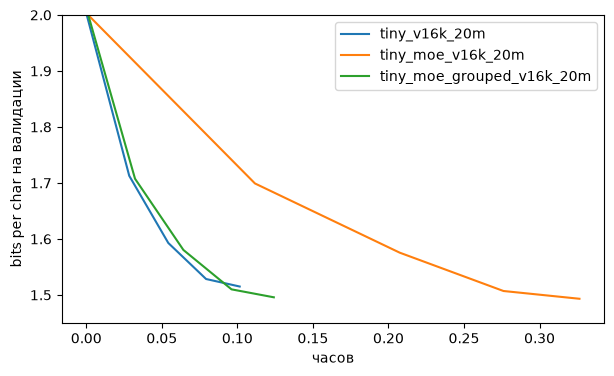

In [11]:
plot_bpc(moe_small, (1.45, 2.0), by_time=True)

-  MoE чуть лучше dense: 1.493 против 1.515 bits per char
- эксперты из transformers на MPS медленные
    - используется torch+python имплементация, есть даже цикл по экспертам на питоне
    - свои эксперты на grouped_mm из torch 2.15 rc почти в 2 раза быстрее:
        - 37k против 21k токенов/с
        - качество то же
    - в torch 2.15 rc оказалось есть и баги (или погрешности накопились)
        - grouped_mm внутри torch.compile дает неверные градиенты
        - поэтому выключил в этом месте compile

## 5. Больше данных и большие модели

Трейн v2:
- добавил все открытые чувашские корпуса, которые нашел (chuvash_llm/add_extra_data.py)
- 135M токенов вместо 46M
- валидацию не трогал

Четыре модели на корпусе v2, одинаковое расписание lr и размер батча:
- large — dense, 118M
- large_moe_v16k_data2 — MoE с теми же числом активных параметров, что у large, 321M параметров
    - ограничил 6 часами обучения (меньше степов чем у large)
- large_moe_v16k_data2_148m — та же large_moe_v16k_data2, но на всех 148M токенов
- xl — dense, подобрал размер так, чтобы скорость была как у large_moe_v16k_data2

In [12]:
big = ['large_v16k_data2', 'large_moe_v16k_data2', 'large_moe_v16k_data2_148m', 'xl_v16k_data2']

summary(['medium_v16k'] + big)

,"параметров, M","токенов, M",токенов/с,часов,bits/char,acc_calib
модель,,,,,,
medium_v16k,68.9,60,11198,1.6,1.2448,0.375
large_v16k_data2,117.6,148,7246,5.8,1.1625,0.458
large_moe_v16k_data2,320.6,116,5904,5.6,1.1766,0.490
large_moe_v16k_data2_148m,320.6,148,5950,7.0,1.1496,0.438
xl_v16k_data2,145.9,148,5960,7.0,1.1550,0.438


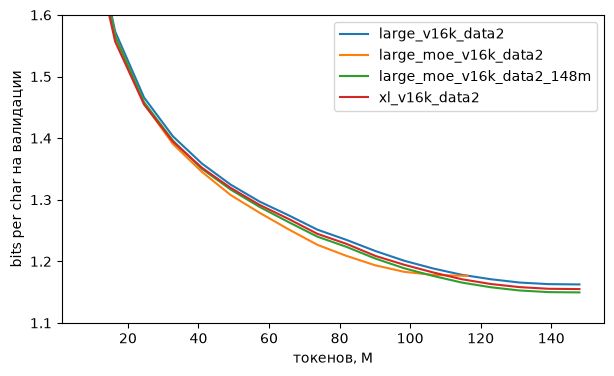

In [13]:
plot_bpc(big, (1.1, 1.6))

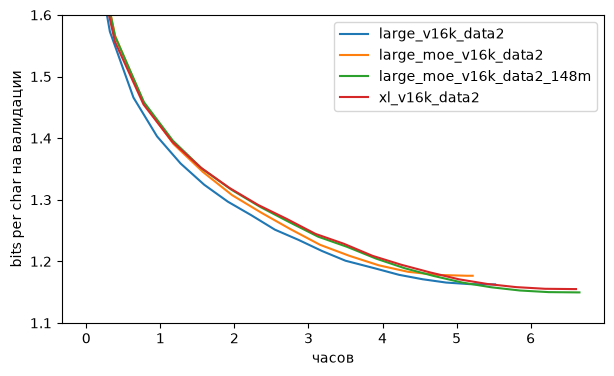

In [14]:
plot_bpc(big, (1.1, 1.6), by_time=True)

- Больше всего дали данные:
    - medium на v1 1.245 -> large на v2 1.163

- На одинаковом числе токенов в трейне MoE лучше dense:
    - 1.150 против 1.163 у large с тем же числом активных параметров
    - 1.150 против 1.155 у xl, который учится с той же скоростью
    - разница маленькая, но держится на всех замерах с ~40M токенов

- Если ограничить время 6 часами, наоборот:
    - large выигрывает 1.163 против 1.177
    - dense быстрее и успевает увидеть на 27% больше токенов

- MoE ест больше памяти:
    - веса + градиенты + Adam для 321M параметров ≈ 5.1 GB
    - у xl 2.3 GB

## 6. Проверка знания фактов

- Даю модели промпт и считаю вероятность увидеть каждое из 4 возможных продолжений. Считаю за 1, если наибольший скор был отдан правильному варианту.

- Добавил замеры качества случайной модели:
    - просэмплировал 30 моделей со случайными весами, архитектура как у large
    - chuvash_llm/random_controls.py

Случайные веса: в среднем 0.275, от 0.198 до 0.385


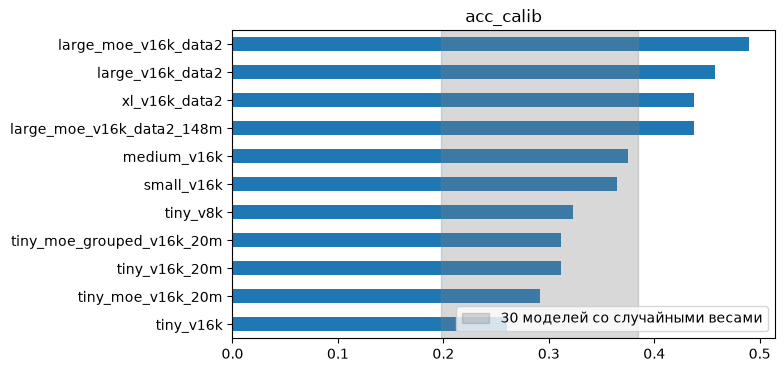

In [15]:
random = json.load(open('results/random_controls.json'))['acc_calib']
print(f'Случайные веса: в среднем {np.mean(random):.3f}, от {min(random)} до {max(random)}')

facts = pd.Series({name: r['summary']['acc_calib'] for name, r in bench.items()})
facts = facts.sort_values()

facts.plot.barh(figsize=(7, 4), title='acc_calib')
plt.axvspan(min(random), max(random), color='gray', alpha=0.3, label='30 моделей со случайными весами')
plt.legend(loc='lower right')
plt.show()

In [17]:
pd.DataFrame({
    'acc_calib': facts,
    'случайных не хуже (из 30)': [sum(r >= v for r in random) for v in facts],
})

,acc_calib,случайных не хуже (из 30)
tiny_v16k,0.260,18
tiny_moe_v16k_20m,0.292,14
tiny_v16k_20m,0.312,6
tiny_moe_grouped_v16k_20m,0.312,6
tiny_v8k,0.323,3
small_v16k,0.365,1
medium_v16k,0.375,1
large_moe_v16k_data2_148m,0.438,0
xl_v16k_data2,0.438,0
large_v16k_data2,0.458,0


- Большие модели (0.44–0.49) выше всех 30 случайных
    - смогли выучить часть фактов
- small и medium на верхней границе шума
- tiny внутри шума
- Между большими моделями разница ~5 промптов из 96
    - сравнимо с разбросом случайных моделей
    - поэтому MoE и dense не различимы по этой метрике